# Performance

`mboostrs` reproduces the numerical results of R `mboost` and computes them
through several optimized engine routes. The engine is written in Rust; the
Rust libraries named on this page are Rayon (a data-parallelism library that
provides a work-stealing thread pool), faer (a pure-Rust dense linear-algebra
library), ndarray (the Rust n-dimensional array type used at the binding
boundary) and PyO3 (the library that exposes Rust functions to Python). Speed
comparisons between implementations are valid only when both sides perform the
same operation; the structured benchmark records described under "Reproducible
benchmarks" provide such comparisons.

## Cost of a fit

A boosting fit is $m_{\text{stop}}$ iterations (boosting steps), each fitting every
base learner to the current negative gradient. The cost is therefore
$O\big(m_{\text{stop}} \cdot \sum_j (\text{cost of one } \texttt{fit\_step}_j)\big)$.
The optimizations all target that inner term.

Two terms are used in the rest of this page. The penalized Gram matrix of a learner with design $B$,
observation weights $W$ and penalty $P$ is $B^\top W B + \lambda P$; solving
with it gives the learner's coefficients. The in-bag risk is the loss evaluated
on the observations with positive weight, the default `risk="inbag"`; the
out-of-bag risk (`risk="oobag"`) is evaluated on the observations with zero
weight.

## Main optimizations

1. **Factorize once, back-solve per step.** The penalized Gram matrix of each
   learner is decomposed (Cholesky) at preparation time; each step is an
   $O(p^2)$ back-substitution, or an $O(1)$ division for a single-column `bols`
   learner, in place of an $O(p^3)$ re-factorization. This is the dominant
   saving for spline-heavy models ([](engine.ipynb), [](linear_algebra.ipynb)).

2. **Reusable per-step storage.** The predictor, gradient, and per-learner scratch
   buffers are allocated once and reused; `fit_step_ref` returns slices into them.
   When block learners are evaluated in parallel, each candidate keeps its
   coefficient vector in a buffer owned by the learner, and the parallel
   reduction compares only scores and learner indices. The engine copies the
   coefficients of the selected learner once, after the parallel section ends,
   so no coefficient vector is allocated for the learners that are not selected.

3. **`faer` dense kernels.** faer provides SIMD-accelerated, cache-aware matrix
   multiplication and Cholesky factorization in pure Rust, so the wheels need no
   BLAS library. Heavy operations stay in column-major `faer` form; conversion
   between `ndarray` and `faer` happens once.

4. **Cross-Gram cache (Gaussian fast path).** For Gaussian models with in-bag
   risk whose prepared learners are all of the kinds `ScalarBols`, `BlockBols`,
   `BmonoBbs` or `Btree` (see "Complexity-aware learner specialization"), with
   at least one block learner, no component subsampling and no per-row offset
   vector, the engine precomputes the cross-Gram matrices (the weighted products of the design matrices of two learners) $C_{jw} = B_j^\top W B_w$ between every
   pair of learners and updates each learner's right-hand side $B_j^\top W r$ in
   $O(p^2)$ per iteration, in place of projecting the $n$-vector residual $r$
   through each design matrix. This removes the $O(n \cdot p)$ matrix-vector
   product per learner per iteration. The resulting speed ratio depends on the
   number of learners, the basis width, and how the setup cost is spread over
   $m_{\text{stop}}$; the live comparison at the end of "Reproducible
   benchmarks" measures it on the reader's machine. Smooth stability selection
   uses the same route and skips the retention of coefficients and risk and the
   final reconstruction of fitted values, which it does not need. See
   [](engine.ipynb) for the algorithm.

5. **Parallel folds.** `cvrisk` runs its $B$ folds in parallel (each an
   independent refit), so cross-validation scales with cores. The LSS
   (location, scale and shape) counterparts (`cvrisk` over the per-parameter
   `mstop` grid, and stability selection for both `glmboostLSS` and
   `gamboostLSS`) parallelize their fold loops the same way; results are
   collected in fold order, so they are identical to a single-threaded run.

6. **Shared basis construction across CV folds.** Each fold of a smooth GAM
   cross-validation still runs `df_to_lambda` (the search for the penalty that
   gives the requested degrees of freedom) and refactorizes each learner under
   the fold's weights. The basis itself does not depend on the fold weights:
   the Python `gamboost` CV path computes the `bbs`/`bspatial` basis
   construction, by-variable multiplication, tensor products, and spectral
   centering once per CV call and reuses them in every fold.

7. **Kronecker identity specialization.** Multinomial `bols`/`bbs` learners
   usually have $X_2 = I_{K-1}$. The engine detects that case and evaluates
   per-class dot products directly in place of the general
   $X_1 B X_2^\top$ product.

## Fused gradient and risk

Families implement `ngradient_and_risk`, computing the negative gradient and the
running risk in a single pass over the data and sharing the expensive transforms
(exponentials, link evaluations). This replaces two passes over the data with
one.

## Complexity-aware learner specialization

The `PreparedLearner` enum (the engine's internal representation of a prepared
base learner) specializes by structure so the common cases are cheap:

- `ScalarBols` (single column) uses no matrices: a dot product and a
  division per step, so `glmboost` over thousands of columns costs $O(n)$ per
  learner per iteration.
- `BlockBols` keeps the design and $WX^\top$ in `faer` and reuses one Cholesky
  factor.
- `Btree` searches splits in a single scan over sorted values, with per-step
  cost $O(np)$ (see [](base_learners.ipynb)). On the Gaussian fast path a tree
  is fitted to an explicit residual beside the Gram updates.

## Numerical agreement with R

The optimizations perform the same arithmetic as R `mboost` with more reuse of
factorizations, a different memory layout and faster kernels; they use no
approximation. Parity tests assert agreement with R to about $10^{-6}$ or
tighter.

## Parallelism and cross-validation

The Rayon thread pool runs all parallel work: `cvrisk` fold loops, `confint`
bootstrap replicates, and stability selection. For $B$ folds on $C$ cores the
wall time scales as about $B/C$, plus the per-fold learner rebuild cost (each
fold re-solves `df_to_lambda` under the fold weights). The LSS `cvrisk` variants
([](lss_engine.ipynb)) parallelize the same way.

```{list-table}
:header-rows: 1

* - Operation
  - Parallelism control
  - Scope
* - `cvrisk`, `cvrisk_glmboostLSS`, `cvrisk_gamboostLSS`
  - `parallel=True` (default)
  - Rayon thread pool
* - `confint`
  - `n_jobs=` (default: Rayon's core count)
  - Number of simultaneous bootstrap refits
* - Global cap
  - `RAYON_NUM_THREADS` env var before import
  - All Rayon pools in the process
```

Pass `parallel=False` to run `cvrisk` folds sequentially, for example inside a
`joblib` workflow that already occupies all cores, to avoid running more threads
than cores. The thread pool is initialized once per process; setting
`RAYON_NUM_THREADS` before importing `mboostrs` is the most reliable way to cap
parallelism globally.

Selection among block learners runs in parallel only when the model has at
least 10 block learners. Below that count, Rayon's scheduling cost exceeds the
time of the independent solves. The threshold comes from candidate scans over
`bbs` (P-spline) learners at $n=2{,}000$ on the development machine:

- at about 10 learners parallel selection first became faster than sequential
  selection (median 124.9 against 129.3 microseconds);
- at 50 learners the medians were 446.9 microseconds parallel against 655.4
  sequential;
- with the threshold, full Poisson fits with 2 and 3 learners have 27.6% and
  22.0% lower median times than with parallel selection always on, and fits
  with 10 and 50 learners are statistically unchanged.

The reuse of candidate buffers (item 2 of "Main optimizations") on its own
reduces fit time by about 0.5 to 1% at the larger learner counts.

## Analytical cost model

The cost model predicts different hotspots depending on whether the Gaussian
fast path is active. The fresh-process stage profile in "Measured development
artifacts" tests those predictions with exclusive (non-overlapping) stage
intervals from the execution report.

### Gaussian fast path (Gram update)

The fast path does no $O(n)$ gradient scan. Per iteration:

1. **Per-learner back-solve** ($\sim O(\sum p_j^2)$): each learner solves
   $G_j \beta_j = s_j$ against its cached Cholesky factor. For `ScalarBols`
   this is a single division; for `BlockBols` it is $O(p_j^2)$.
2. **Per-learner SSE** ($\sim O(\sum p_j^2)$): the residual-SSE identity
   $\text{SSE}_j = \text{wu2} - \beta_j^\top s_j - \beta_j^\top P_j \beta_j$,
   computed without touching the $n$-vector. `wu2`, the weighted sum of squared
   residuals, is updated incrementally.
3. **Selection** ($\sim O(J)$): comparing per-learner SSEs.
4. **Right-hand-side update** ($\sim O(\sum_w p_w p_{j^\star})$): all learners'
   right-hand sides are updated through the precomputed cross-Gram matrices.
   This is the only non-trivial cost, and it is $O(p^2)$ in place of $O(np)$.
5. **Reconstruct fitted values** ($O(n \cdot P)$, once at the end): the predictor
   is rebuilt from the selection path and the per-learner designs.

This structure predicts a loop dominated by back-solves and cross-Gram updates;
the "Exclusive measured stage profile" figure reports the measured shares.

### General loop (all other models)

1. **Family gradient** ($\sim O(n)$): `ngradient_and_risk` evaluates the loss,
   its derivative, and accumulates the risk in one pass. For families with
   expensive link functions (Binomial, CoxPH with risk-set sorting) this is the
   largest single cost.
2. **Per-learner matrix-vector product and back-solve**
   ($\sim O(\sum (n p_j + p_j^2))$): each learner's `fit_step_ref` projects the
   residual through $B_j^\top W$ ($O(np_j)$) and then back-solves ($O(p_j^2)$).
   The product dominates for $p_j \ll n$ and is the main candidate for further
   optimization.
3. **Selection** ($\sim O(J)$): comparing the per-learner SSEs to find the
   minimum. Negligible for any realistic $J$.
4. **Update** ($\sim O(n)$): adding $\nu \cdot \text{pred}_{j^\star}$ to the
   running predictor, where $\nu$ is the step length. Also negligible.

This structure predicts that the per-learner pass over the $n$-vector residual
dominates; the "Exclusive measured stage profile" figure reports the measured
share.

## Reproducible benchmarks

`benches/scenarios.json` is the scenario catalog. All 32 scenarios are
implemented, including separate serial and default-thread stability-selection
scenarios and a fresh-process 1/2/4/8-thread scaling sweep whose outputs have
identical digests. `benches/bench_all.py` runs the cross-language scenarios and
validates its JSON output against `docs/schemas/benchmark-result.schema.json`.
Every result retains raw repetitions, warmup policy, commit and package
versions, compiler flags, CPU and OS, thread settings, input digest, individual
output digests, one shared correctness digest, median, MAD and bootstrap
interval, and an explicit status for resident-memory (RSS) and allocation
measurements.

The metadata also copies `mb.build_info()` from the loaded extension: a digest
of the native Rust sources and Cargo configuration, the build-time Git revision
and whether the working copy had uncommitted changes, compiler, target, CPU
features, Cargo features, profile, and ABI schema. `mb.__version__` is the
release version. Two binaries can both be version 0.1.3 while different
`build_id` values show that one used other sources, compiler settings, or target
features; inspecting the source checkout cannot establish which built extension
Python loaded. R exposes the same record through `mboostrs_build_info()`.

Cross-language scenarios run a separate warmed allocation pass for each
implementation. Memray records system and CPython allocator events across
Python, Rust, and Rayon threads; Rprofmem records R allocator events, including
those of the parent process and of forked workers for default-parallel CV. Each
count names its profiler and the allocations that profiler measures. The R
profiler excludes memory obtained outside R's allocator API, so these counts
describe each implementation separately and are not combined into a ratio.

Cross-language timing requires both sides to perform the complete same
operation. The CV comparison starts from an already-fitted model on both sides
and uses identical folds; serial-against-serial and default-against-default
thread settings have separate scenario IDs. This chapter reports no
cross-language speed ratio, because no structured snapshot from a build without
uncommitted changes exists for it.

The live comparison of the Gram and general routes runs on the machine that
builds the book. It reports local route behaviour only and is not a
cross-language benchmark.

In [1]:
import time
import numpy as np
import polars as pl
import mboostrs as mb

rng = np.random.default_rng(0)


def make_smooth_data(n, n_learners):
    """n observations, n_learners bbs(x, df=4) terms, additive sinusoidal signal."""
    data = {}
    y = rng.normal(size=n)
    terms = []
    for j in range(n_learners):
        xj = rng.normal(size=n)
        data[f"x{j}"] = xj
        y = y + 0.3 * np.sin(xj)
        terms.append(f"bbs(x{j}, df=4)")
    data["y"] = y
    return "y ~ " + " + ".join(terms), data


def best_of(fn, reps=5):
    fn()  # warm up (JIT-free in Rust, but keeps allocator/cache state comparable)
    return min(_time_once(fn) for _ in range(reps))


def _time_once(fn):
    t0 = time.perf_counter()
    fn()
    return time.perf_counter() - t0


rows = []
for n_learners in [2, 10]:
    formula, data = make_smooth_data(n=2000, n_learners=n_learners)
    # risk="inbag" (the default) takes the Gaussian Gram-update fast path;
    # risk="oobag" forces the general per-step projection loop on the exact
    # same model, isolating the fast path's effect from everything else.
    t_gram = best_of(lambda: mb.gamboost(
        formula, data=data, family=mb.Gaussian(),
        control=mb.boost_control(mstop=200, nu=0.1, risk="inbag")))
    t_general = best_of(lambda: mb.gamboost(
        formula, data=data, family=mb.Gaussian(),
        control=mb.boost_control(mstop=200, nu=0.1, risk="oobag")))
    rows.append({
        "n_learners": n_learners, "gram path (ms)": t_gram * 1000,
        "general path (ms)": t_general * 1000, "speedup": t_general / t_gram,
    })

pl.DataFrame(rows)


n_learners,gram path (ms),general path (ms),speedup
i64,f64,f64,f64
2,1.521042,5.873083,3.861224
10,4.757708,12.229667,2.570495


The table compares the two routes on the same model on the machine that builds
the book. More learners add per-iteration back-solve and SSE work relative to
the projection cost the Gram update saves. Ratios vary by hardware; comparisons
across machines require the structured benchmark records.

## Memory scaling: the Gaussian fast path

`gamboost` with a Gaussian family, in-bag risk, and learners that the route
supports (item 4 of "Main optimizations") uses the Gram-update fast path (see [](engine.ipynb)), which avoids re-projecting the
residual each iteration. The engine computes the upper triangle of the cross-Gram
matrices $C_{jw} = B_j^\top W B_w$ and fills the lower triangle by transposition,
so the matrix products are not computed twice. It stores the symmetric entries
explicitly for cheap indexing in the inner loop, so memory is $O(J^2 p^2)$.
For $J \approx 10$ spline learners with $p_j \approx 24$, this is under 1 MB.
For $J \approx 10^3$ spline learners with $p_j \approx 20$, the cross-Gram cache
is several GB. The fast path therefore scales to a few hundred spline learners
before memory becomes a concern; `glmboost` models with only single-column
learners use the packed-scalar path, which stores no cross-Gram matrices.
The engine falls back to the standard per-step projection loop when any
learner is of an unsupported kind (for example a binned, hinge, Kronecker or
factored-block learner), when the family is not Gaussian, or when the risk
criterion is not in-bag; the execution report of the fit names the reason.

## Measured development artifacts

The records in this section were measured with mboostrs 0.1.3 built from a
working copy with uncommitted changes, so they describe that development build
and no released package.

`benches/profile_memory.py` runs every point in a fresh process. It records
exclusive preparation, core-setup, cross-Gram, iteration, reconstruction, and
binding intervals from `ExecutionReport` (the per-fit timing record the engine
returns); process peak resident memory (RSS) from `ru_maxrss`; and the exact
bytes of the retained factor and cross-Gram caches. A counting global
allocator separately counts all allocation events of a core fit after warmup;
these counts include the construction of the retained result path and of the
Gram cache as well as the allocations in the steady-state iteration loop.

`benches/bench_thread_scaling.py` runs each Rayon thread setting in a fresh
process. The [raw scaling record](../data/thread-scaling-2026-07-15.json)
contains every repetition and an identical correctness digest for one, two,
four, eight, and the default number of threads. Running the script on another
build measures that build with the same thread settings and checks.

route,n,learners,peak_rss_mib,incremental_peak_mib,retained_cache_kib
str,i64,i64,f64,f64,f64
"""gaussian_gram""",1000,2,155.28125,4.0,27.0
"""gaussian_gram""",1000,10,165.4375,14.234375,495.0
"""gaussian_gram""",5000,2,165.140625,13.96875,27.0
"""gaussian_gram""",5000,10,213.921875,62.59375,495.0
"""gaussian_gram""",10000,2,175.15625,23.921875,27.0
"""gaussian_gram""",10000,10,272.046875,120.828125,495.0
"""general_block""",1000,2,154.5,3.375,9.0
"""general_block""",5000,2,161.625,10.34375,9.0
"""general_block""",10000,2,167.84375,16.703125,9.0


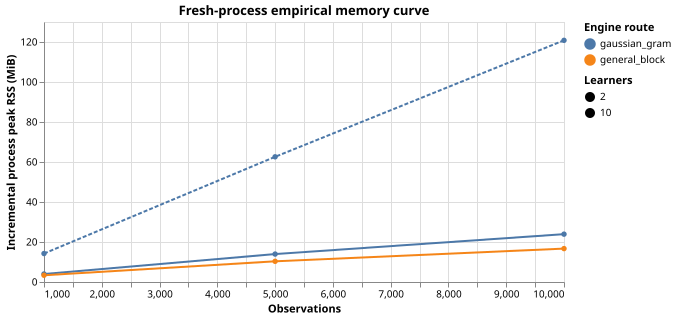

phase,gaussian_gram,general_block
str,f64,f64
"""basis""",0.336692,0.074385
"""factorization""",0.000505,0.000123
"""binding""",0.000369,0.000553
"""core_setup""",0.337399,0.002245
"""cross_gram""",0.294537,0.0
"""iterations""",0.024017,0.922694
"""reconstruction""",0.00648,0.0


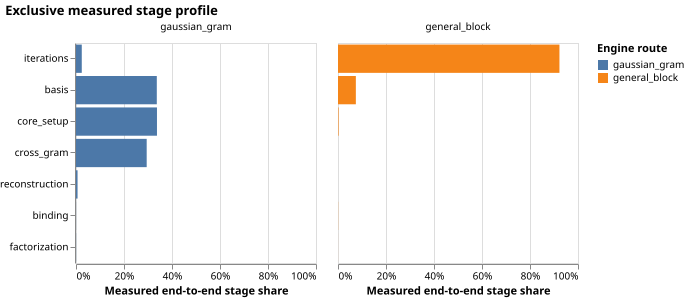

route,learners,allocations
str,i64,i64
"""packed_scalar""",10,217
"""gaussian_gram""",10,2456


threads,median_ms,ci95_low_ms,ci95_high_ms,speedup_vs_one
i64,f64,f64,f64,f64
1,17.88575,17.510917,18.03625,1.0
2,9.7085,9.663625,9.746417,1.842277
4,6.597,6.585875,6.641333,2.711194
8,5.1005,5.064708,5.172709,3.506666


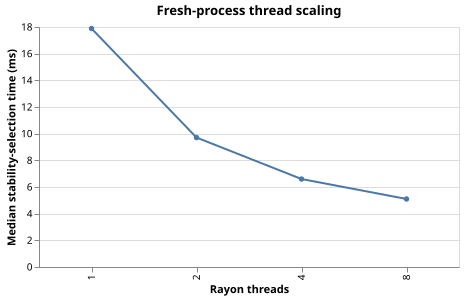

In [2]:
import json
from pathlib import Path
import altair as alt
import polars as pl

snapshot_path = next(path for path in [
    Path('../data/profile-memory-2026-07-15.json'),
    Path('docs/book/data/profile-memory-2026-07-15.json'),
] if path.exists())
snapshot = json.loads(snapshot_path.read_text())
rows = pl.DataFrame(snapshot['results']).with_columns(
    (pl.col('peak_rss_bytes') / 2**20).alias('peak_rss_mib'),
    (pl.col('incremental_peak_rss_bytes') / 2**20).alias('incremental_peak_mib'),
    ((pl.col('factor_cache_bytes') + pl.col('gram_cache_bytes')) / 2**10).alias('retained_cache_kib'),
)
display(rows.select('route', 'n', 'learners', 'peak_rss_mib', 'incremental_peak_mib', 'retained_cache_kib'))

memory_chart = alt.Chart(rows).mark_line(point=True).encode(
    x=alt.X('n:Q', title='Observations'),
    y=alt.Y('incremental_peak_mib:Q', title='Incremental process peak RSS (MiB)'),
    color=alt.Color('route:N', title='Engine route'),
    strokeDash=alt.StrokeDash('learners:N', title='Learners'),
).properties(width=520, height=260, title='Fresh-process empirical memory curve')
display(memory_chart)

representatives = rows.filter(
    ((pl.col('route') == 'gaussian_gram') & (pl.col('n') == 10000) & (pl.col('learners') == 10))
    | ((pl.col('route') == 'general_block') & (pl.col('n') == 10000))
)
profile_rows = []
for row in representatives.iter_rows(named=True):
    for phase, share in row['phase_share'].items():
        profile_rows.append({'route': row['route'], 'phase': phase, 'share': share})
profile = pl.DataFrame(profile_rows)
display(profile.pivot(on='route', index='phase', values='share').fill_null(0))
display(alt.Chart(profile).mark_bar().encode(
    x=alt.X('share:Q', axis=alt.Axis(format='%'), title='Measured end-to-end stage share'),
    y=alt.Y('phase:N', sort='-x', title=None),
    color=alt.Color('route:N', title='Engine route'),
    column=alt.Column('route:N', title=None),
).properties(width=240, height=220, title='Exclusive measured stage profile'))

allocation_path = next(path for path in [
    Path('../data/allocation-2026-07-15.json'),
    Path('docs/book/data/allocation-2026-07-15.json'),
] if path.exists())
allocations = json.loads(allocation_path.read_text())
display(pl.DataFrame([
    {'route': route, **values}
    for route, values in allocations.items()
    if isinstance(values, dict)
]))

thread_path = next(path for path in [
    Path('../data/thread-scaling-2026-07-15.json'),
    Path('docs/book/data/thread-scaling-2026-07-15.json'),
] if path.exists())
thread_snapshot = json.loads(thread_path.read_text())
scaling = next(row for row in thread_snapshot['results']
               if row['scenario_id'] == 'scaling.thread_count.core')
thread_rows = pl.DataFrame([
    {
        'threads': int(item['implementation'].rsplit('-', 1)[1]),
        'median_ms': 1000 * item['summary']['median_seconds'],
        'ci95_low_ms': 1000 * item['summary']['ci95_low_seconds'],
        'ci95_high_ms': 1000 * item['summary']['ci95_high_seconds'],
    }
    for item in scaling['measurements']
])
one_thread_ms = thread_rows.item(0, 'median_ms')
thread_rows = thread_rows.with_columns(
    (one_thread_ms / pl.col('median_ms')).alias('speedup_vs_one')
)
display(thread_rows)
display(alt.Chart(thread_rows).mark_line(point=True).encode(
    x=alt.X('threads:O', title='Rayon threads'),
    y=alt.Y('median_ms:Q', title='Median stability-selection time (ms)'),
    tooltip=['threads', alt.Tooltip('median_ms', format='.3f'),
             alt.Tooltip('speedup_vs_one', format='.2f')],
).properties(width=420, height=240, title='Fresh-process thread scaling'))


## Comparative studies

The [distributional comparison](../cases/distributional_comparison.ipynb) records the cost of tuning and predicting with four modeling procedures alongside their predictive scores. Those procedures perform different numerical work, so their costs are not implementation speed ratios.

## See also

- [](engine.ipynb): the inner loop and the Gaussian Gram-update mechanics.
- [](architecture.ipynb): the `PreparedLearner` enum that implements the
  complexity-aware specialization.
- [](linear_algebra.ipynb): the `GramSolver` and the `df_to_lambda` solve that
  dominates per-learner preparation cost.
- `benches/bench_all.py`: the Python benchmarking script against R `mboost`.
- `crates/mboostrs-core/benches/bench_core.rs`: Criterion (Rust
  micro-benchmark harness) benchmarks of setup, fit (Gram and general routes),
  `cvrisk`, and per-family cost.
- [](../methodology/functional_gradient_boosting): the algorithm whose
  per-step cost this chapter measures (gradient, selection, update).
- [](../methodology/model_selection): why the fold-parallel `cvrisk` speeds up
  almost linearly in the number of cores (folds share no state).